<a href="https://colab.research.google.com/github/antoniosolis4536-collab/MIAAD/blob/main/Practica_02_Clases_Desbalanceadas_SEM13_274706.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea: Tratamiento de clases no balanceadas (compustat)

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre:** Antonio Ismael Solís Martínez  
**Matrícula:** 274706

**Objetivo:** comparar un SVM base contra el mismo SVM entrenado con dos técnicas de balanceo (SMOTEENN y One-Sided Selection), con validación cruzada estratificada de 5 particiones y usando `Pipeline` para que el balanceo y el escalado se hagan solo con los datos de entrenamiento de cada fold (sin data leakage).

## Preparación: bibliotecas y carga de datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/drive/MyDrive/ClassFiles/compustat.csv")
print("Forma:", df.shape)
df.head()


Forma: (13657, 22)


,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [ ]:
# El primer atributo (idx) es un índice y se ignora; el último (label) es la clase.
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

print("Predictores:", X.shape[1], "->", list(X.columns))
print("Clase:", y.name)
print("Valores nulos:", df.isnull().sum().sum())


Predictores: 20 -> ['at0', 'at1', 'at2', 'at3', 'at4', 'at5', 'at6', 'at7', 'at8', 'at9', 'at10', 'at11', 'at12', 'at13', 'at14', 'at15', 'at16', 'at17', 'at18', 'at19']
Clase: label
Valores nulos: 0


## 1. Análisis Exploratorio de Datos (AED)

       registros  porcentaje
label                       
0          13137       96.19
1            520        3.81

Razón mayoritaria / minoritaria: 25.3 a 1


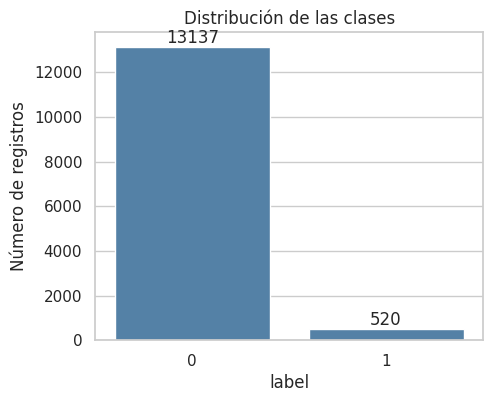

In [ ]:
# Distribución de clases
conteo = y.value_counts().sort_index()
porcentaje = y.value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"registros": conteo, "porcentaje": porcentaje.round(2)}))
print(f"\nRazón mayoritaria / minoritaria: {conteo.max() / conteo.min():.1f} a 1")

plt.figure(figsize=(5, 4))
ax = sns.barplot(x=conteo.index.astype(str), y=conteo.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Distribución de las clases")
plt.xlabel("label")
plt.ylabel("Número de registros")
plt.show()


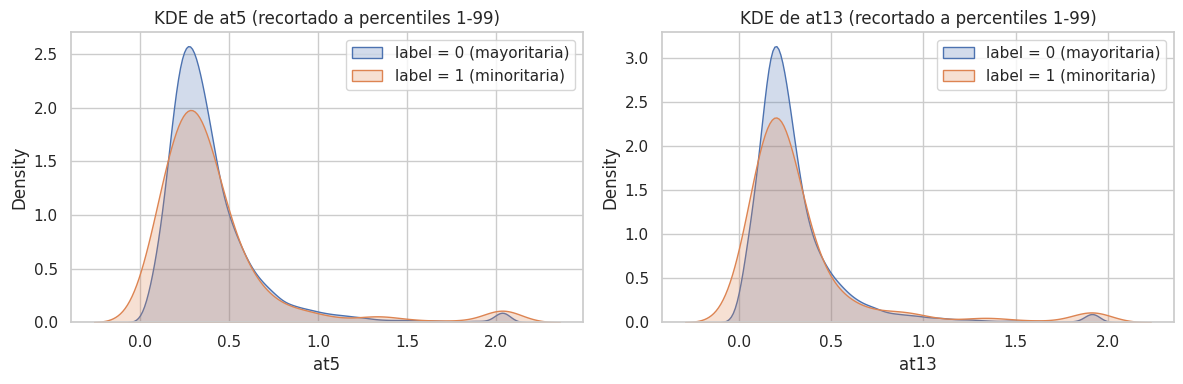

label               0        1
at5  count  13137.000  520.000
     mean       0.834    2.517
     std       30.106   27.191
     min        0.000    0.033
     25%        0.233    0.213
     50%        0.327    0.317
     75%        0.468    0.450
     max     3296.157  510.152
at13 count  13137.000  520.000
     mean       0.723    2.442
     std       29.962   27.197
     min       -7.927    0.022
     25%        0.163    0.155
     50%        0.237    0.223
     75%        0.353    0.352
     max     3296.157  510.152

In [ ]:
# Diagramas de densidad KDE de los atributos at5 y at13.
# Estos atributos tienen valores extremos (máximo de 3,296) que aplastan la gráfica,
# así que para dibujar se recorta cada atributo entre sus percentiles 1 y 99.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, atributo in zip(ejes, ["at5", "at13"]):
    inferior, superior = X[atributo].quantile([0.01, 0.99])
    recortado = X[atributo].clip(inferior, superior)
    sns.kdeplot(x=recortado[y == 0], label="label = 0 (mayoritaria)", fill=True, common_norm=False, ax=eje)
    sns.kdeplot(x=recortado[y == 1], label="label = 1 (minoritaria)", fill=True, common_norm=False, ax=eje)
    eje.set_title(f"KDE de {atributo} (recortado a percentiles 1-99)")
    eje.legend()
plt.tight_layout()
plt.show()

X[["at5", "at13"]].groupby(y).describe().T.round(3)


**Análisis del desbalance:** el conjunto tiene 13,657 registros: 13,137 de la clase 0 (96.19%) y solo 520 de la clase 1 (3.81%). La razón es de 25.3 a 1, o sea que es un desbalance fuerte. Un modelo que siempre dijera "clase 0" tendría una exactitud de 96.19% sin detectar ni un solo caso de la clase 1.

**KDE de at5 y at13:** las dos clases tienen casi la misma forma, con el pico cerca de 0.3 (at5) y 0.2 (at13). Las medianas son prácticamente iguales (at5: 0.327 en la clase 0 contra 0.317 en la clase 1; at13: 0.237 contra 0.223). La clase 1 tiene un poco más de masa en valores muy bajos, pero se empalman mucho. Esto sugiere que estos atributos, por sí solos, separan poco las clases, y que el problema va a ser difícil aun con balanceo. Nota: ambos atributos tienen valores extremos (máximo de 3,296), por eso las gráficas se recortaron a los percentiles 1-99; la pequeña "joroba" en 2.0 es el efecto de ese recorte (los valores más altos quedan acumulados en el límite).

## 2. Modelo base (sin tratamiento de desbalance)

In [ ]:
modelo_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# Partición única 80/20 estratificada, solo para esta primera referencia.
# La evaluación completa (validación cruzada de 5 folds) está en la sección 4.
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

modelo_base.fit(X_ent, y_ent)
pred_base = modelo_base.predict(X_pru)

print("Predicciones de clase 1 en prueba:", pred_base.sum(), "de", (y_pru == 1).sum(), "positivos reales")
print(f"Accuracy: {accuracy_score(y_pru, pred_base):.4f}")
print(f"Precision: {precision_score(y_pru, pred_base, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_pru, pred_base, zero_division=0):.4f}")
print(f"F1: {f1_score(y_pru, pred_base, zero_division=0):.4f}")


Predicciones de clase 1 en prueba: 1 de 104 positivos reales
Accuracy: 0.9623
Precision: 1.0000
Recall: 0.0096
F1: 0.0190


**Lectura del baseline:** el SVM base obtiene una accuracy de 0.9623, pero de los 104 casos reales de la clase 1 en la prueba solo predice 1 (recall de 0.0096 y F1 de 0.019). En la práctica el modelo contesta casi siempre "clase 0": la exactitud sale alta porque la clase 0 es el 96% de los datos, no porque el modelo haya aprendido algo de la clase minoritaria. Este es el punto de referencia para comparar.

## 3. Tratamiento de clases no balanceadas (SMOTEENN y One-Sided Selection)

Aquí se aplica cada técnica sobre el **conjunto de entrenamiento** de la partición anterior (nunca sobre la prueba) para ver la nueva distribución y entrenar el SVM. Como las dos técnicas usan distancias (vecinos más cercanos), primero se escalan los datos, con el escalador ajustado solo con el entrenamiento. La evaluación sin fuga con validación cruzada está en la sección 4.

In [ ]:
escalador = StandardScaler().fit(X_ent)
X_ent_esc = escalador.transform(X_ent)
X_pru_esc = escalador.transform(X_pru)

tecnicas = {
    "SMOTEENN": SMOTEENN(random_state=42),
    "One-Sided Selection": OneSidedSelection(random_state=42),
}

print("Original:", dict(y_ent.value_counts().sort_index()))
distribuciones = {"Original": y_ent.value_counts().sort_index()}
resultados_demo = {}
for nombre, tecnica in tecnicas.items():
    X_bal, y_bal = tecnica.fit_resample(X_ent_esc, y_ent)
    distribuciones[nombre] = pd.Series(y_bal).value_counts().sort_index()
    print(f"{nombre}:", dict(pd.Series(y_bal).value_counts().sort_index()))

    svm = SVC(kernel="rbf", C=1.0, gamma="scale").fit(X_bal, y_bal)
    pred = svm.predict(X_pru_esc)
    resultados_demo[nombre] = {
        "accuracy": accuracy_score(y_pru, pred),
        "precision": precision_score(y_pru, pred, zero_division=0),
        "recall": recall_score(y_pru, pred, zero_division=0),
        "f1": f1_score(y_pru, pred, zero_division=0),
    }

pd.DataFrame(resultados_demo).T.round(4)


Original: {0: np.int64(10509), 1: np.int64(416)}
SMOTEENN: {0: np.int64(9349), 1: np.int64(10482)}
One-Sided Selection: {0: np.int64(10240), 1: np.int64(416)}


,accuracy,precision,recall,f1
SMOTEENN,0.8053,0.148,0.8654,0.2528
One-Sided Selection,0.9627,1.000,0.0192,0.0377


       Original  SMOTEENN  One-Sided Selection
label                                         
0         10509      9349                10240
1           416     10482                  416


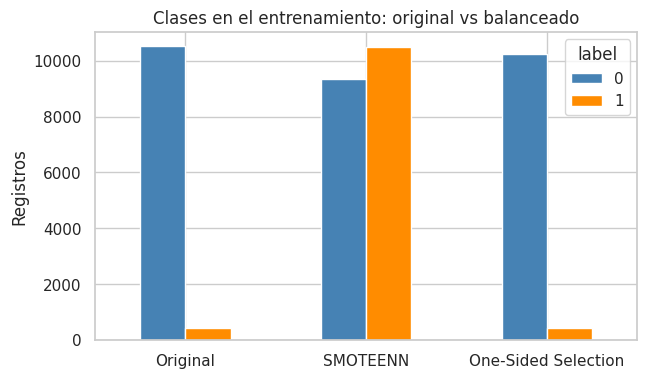

In [ ]:
# Distribución de clases antes y después del balanceo
tabla_dist = pd.DataFrame(distribuciones).fillna(0).astype(int)
tabla_dist.index.name = "label"
print(tabla_dist)

tabla_dist.T.plot(kind="bar", figsize=(7, 4), color=["steelblue", "darkorange"])
plt.title("Clases en el entrenamiento: original vs balanceado")
plt.ylabel("Registros")
plt.xticks(rotation=0)
plt.show()


**Qué hizo cada técnica sobre el entrenamiento** (10,509 de la clase 0 y 416 de la clase 1, o sea 25 a 1):
- **SMOTEENN** combina sobremuestreo y limpieza: SMOTE crea ejemplos sintéticos de la clase 1 y ENN elimina ejemplos ruidosos o muy mezclados con la otra clase. Quedó casi balanceado: 9,349 de la clase 0 y 10,482 de la clase 1.
- **One-Sided Selection** solo submuestrea la clase mayoritaria, quitando ejemplos redundantes o ruidosos cerca de la frontera. Apenas quitó 269 ejemplos (10,509 → 10,240), así que la razón sigue en 24.6 a 1 y no balancea en realidad.

Con una sola partición, el SVM entrenado con SMOTEENN detecta el 86.5% de la clase 1 (recall de 0.865) pero con precision de 0.148 y accuracy de 0.805; con One-Sided Selection el resultado es casi igual al baseline (recall de 0.019). Estos números son solo ilustrativos de una partición; los resultados que cuentan son los de la validación cruzada de la sección 4.

## 4. Entrenamiento y evaluación con validación cruzada estratificada (5 folds) y Pipeline

Cada modelo es un `Pipeline` (escalado → balanceo → SVM). Se usa el `Pipeline` de `imblearn`, porque permite poner el muestreo dentro: así, en cada fold el escalador y la técnica de balanceo se ajustan **solo con los datos de entrenamiento de ese fold**, y el fold de prueba queda con su distribución real y sin tocar. Si se balancearan los datos antes de la validación cruzada, habría copias sintéticas de los mismos pacientes en entrenamiento y prueba (data leakage) y las métricas saldrían infladas.

In [ ]:
modelos = {
    "Baseline": ImbPipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
    ]),
    "SMOTEENN": ImbPipeline([
        ("scaler", StandardScaler()),
        ("balanceo", SMOTEENN(random_state=42)),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
    ]),
    "One-Sided Selection": ImbPipeline([
        ("scaler", StandardScaler()),
        ("balanceo", OneSidedSelection(random_state=42)),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale")),
    ]),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_arr = X.values
y_arr = y.values

metricas_folds = {}
matrices = {}
for nombre, modelo in modelos.items():
    filas = []
    matriz_total = np.zeros((2, 2), dtype=int)
    for fold, (idx_ent, idx_pru) in enumerate(skf.split(X_arr, y_arr), start=1):
        m = clone(modelo)
        m.fit(X_arr[idx_ent], y_arr[idx_ent])
        pred = m.predict(X_arr[idx_pru])
        filas.append({
            "fold": fold,
            "accuracy": accuracy_score(y_arr[idx_pru], pred),
            "precision": precision_score(y_arr[idx_pru], pred, zero_division=0),
            "recall": recall_score(y_arr[idx_pru], pred, zero_division=0),
            "f1": f1_score(y_arr[idx_pru], pred, zero_division=0),
        })
        matriz_total += confusion_matrix(y_arr[idx_pru], pred, labels=[0, 1])
    metricas_folds[nombre] = pd.DataFrame(filas).set_index("fold")
    matrices[nombre] = matriz_total
    print(f"{nombre} listo")


Baseline listo
SMOTEENN listo
One-Sided Selection listo


## 5. Evaluación de resultados

In [ ]:
# Métricas por fold de cada modelo
for nombre, tabla in metricas_folds.items():
    print(nombre)
    display(tabla.round(4))


Baseline


,accuracy,precision,recall,f1
fold,,,,
1,0.9619,0.0,0.0000,0.0000
2,0.9619,0.0,0.0000,0.0000
3,0.9623,1.0,0.0096,0.0190
4,0.9627,1.0,0.0192,0.0377
5,0.9623,1.0,0.0096,0.0190


SMOTEENN


,accuracy,precision,recall,f1
fold,,,,
1,0.8166,0.1524,0.8365,0.2578
2,0.8049,0.1308,0.7308,0.2219
3,0.8078,0.1352,0.7500,0.2291
4,0.8155,0.1503,0.8269,0.2544
5,0.8111,0.1508,0.8558,0.2565


One-Sided Selection


,accuracy,precision,recall,f1
fold,,,,
1,0.9623,1.0000,0.0096,0.0190
2,0.9619,0.5000,0.0096,0.0189
3,0.9623,1.0000,0.0096,0.0190
4,0.9623,0.6667,0.0192,0.0374
5,0.9623,1.0000,0.0096,0.0190


In [ ]:
# Resumen: media y desviación estándar (ddof=1) de las métricas en los 5 folds
resumen = pd.DataFrame({
    nombre: tabla.mean() for nombre, tabla in metricas_folds.items()
}).T
desviacion = pd.DataFrame({
    nombre: tabla.std(ddof=1) for nombre, tabla in metricas_folds.items()
}).T

print("Media de las métricas (5 folds):")
display(resumen.round(4))
print("Desviación estándar:")
display(desviacion.round(4))


Media de las métricas (5 folds):


,accuracy,precision,recall,f1
Baseline,0.9622,0.6000,0.0077,0.0152
SMOTEENN,0.8112,0.1439,0.8000,0.2439
One-Sided Selection,0.9622,0.8333,0.0115,0.0227


Desviación estándar:


,accuracy,precision,recall,f1
Baseline,0.0003,0.5477,0.0080,0.0158
SMOTEENN,0.0050,0.0101,0.0558,0.0171
One-Sided Selection,0.0002,0.2357,0.0043,0.0082


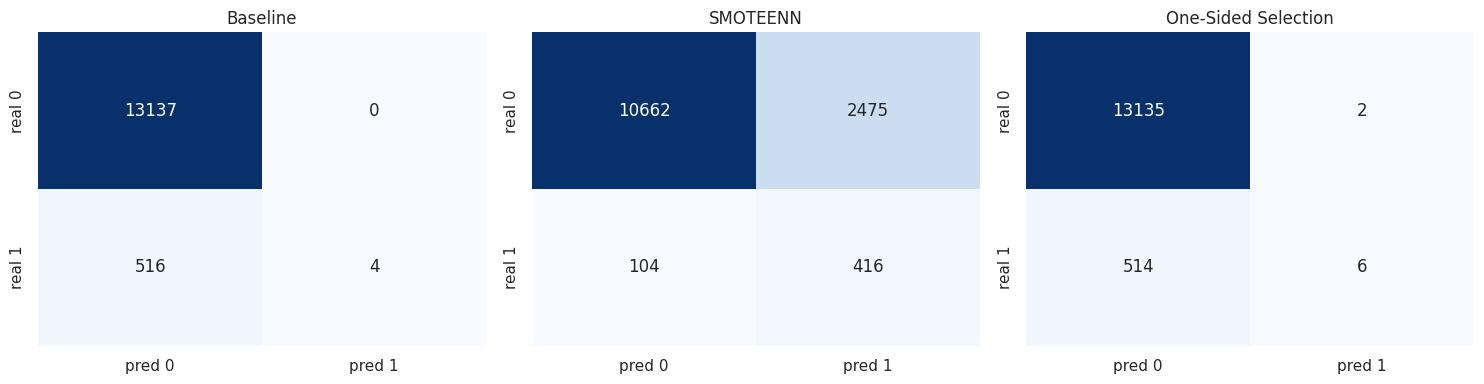

Baseline: TN=13137, FP=0, FN=516, TP=4
SMOTEENN: TN=10662, FP=2475, FN=104, TP=416
One-Sided Selection: TN=13135, FP=2, FN=514, TP=6


In [ ]:
# Matrices de confusión (suma de los 5 folds de prueba; la clase 1 es la minoritaria)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (nombre, matriz) in zip(ejes, matrices.items()):
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eje,
                xticklabels=["pred 0", "pred 1"], yticklabels=["real 0", "real 1"])
    eje.set_title(nombre)
plt.tight_layout()
plt.show()

for nombre, matriz in matrices.items():
    tn, fp, fn, tp = matriz.ravel()
    print(f"{nombre}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")


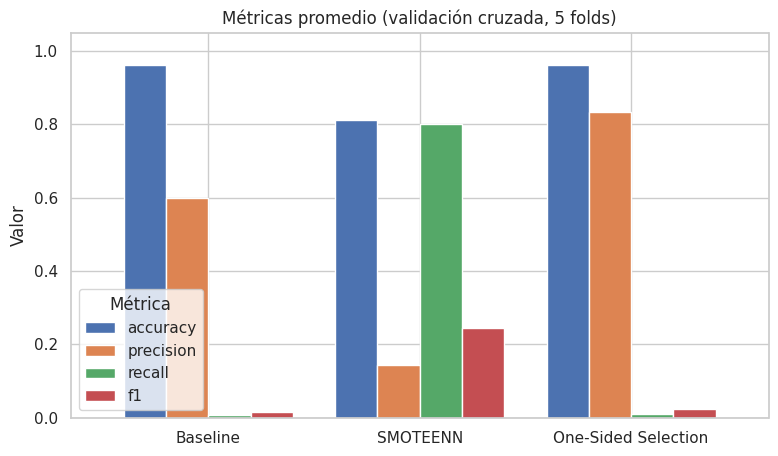

In [ ]:
# Gráfica comparativa de métricas
resumen.plot(kind="bar", figsize=(9, 5), width=0.8)
plt.title("Métricas promedio (validación cruzada, 5 folds)")
plt.ylabel("Valor")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Métrica", loc="lower left")
plt.show()


**Resultados (media de los 5 folds):**

| Modelo | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Baseline | 0.9622 | 0.600 | 0.0077 | 0.0152 |
| SMOTEENN | 0.8112 | 0.1439 | 0.8000 | 0.2439 |
| One-Sided Selection | 0.9622 | 0.833 | 0.0115 | 0.0227 |

**Matrices de confusión (suma de los 5 folds de prueba, 520 casos de la clase 1):**
- **Baseline:** detecta 4 de 520 (TP = 4, FN = 516) y no tiene falsas alarmas (FP = 0).
- **SMOTEENN:** detecta 416 de 520 (TP = 416, FN = 104), pero genera 2,475 falsas alarmas (FP) de 13,137 casos de la clase 0.
- **One-Sided Selection:** detecta 6 de 520 (TP = 6, FN = 514) y tiene 2 falsas alarmas.

**Sobre la precision del baseline y One-Sided Selection:** el promedio por fold (0.60 y 0.83) no es confiable. Estos modelos predicen la clase 1 apenas 4 y 8 veces en total, así que la precision de cada fold depende de uno o dos casos (en dos folds del baseline es 0 porque no predijo ninguna; la desviación estándar es de 0.55 y 0.24). Con las matrices de confusión, la precision total es 4/4 = 1.0 para el baseline y 6/8 = 0.75 para One-Sided Selection, pero con 4 o 6 aciertos de 520 no significa que el modelo sea bueno.

**¿Accuracy es suficiente?** No. El baseline y One-Sided Selection tienen la accuracy más alta (0.9622) y son casi inútiles para el objetivo, porque ignoran el 98-99% de la clase minoritaria. SMOTEENN tiene la accuracy más baja (0.8112) y es el único que detecta la mayoría de la clase 1. Si se juzgara solo por accuracy, se elegiría al peor modelo. Para este problema hay que ver recall, precision, F1 y la matriz de confusión.

## 6. Discusión y conclusiones

**Impacto del desbalance.** Con 25 a 1, el SVM minimiza el error total ignorando a la clase 1: predice casi siempre la clase 0, logra 96.2% de accuracy y un recall de 0.008. El desbalance no daña la accuracy, daña la capacidad de detectar la clase de interés, y por eso la accuracy engaña. Además, los KDE de at5 y at13 muestran que las clases se parecen mucho en esos atributos, lo que hace el problema más difícil.

**SMOTEENN contra One-Sided Selection.**
- **SMOTEENN** sí cambió el comportamiento del modelo: el recall pasó de 0.008 a 0.800 y el F1 de 0.015 a 0.244. El costo es que la precision cayó a 0.144 (2,475 falsas alarmas por 416 aciertos) y la accuracy a 0.811. Al dejar las clases casi balanceadas (9,349 contra 10,482), el SVM deja de ignorar a la clase 1.
- **One-Sided Selection** casi no cambió nada (F1 de 0.023, recall de 0.0115): solo elimina ejemplos de la clase mayoritaria cerca de la frontera o redundantes, quitó apenas 269 de 10,509, y la razón siguió en casi 25 a 1. Es una técnica de limpieza, no de balanceo, y no es suficiente con un desbalance tan fuerte.

**Mejor método.** SMOTEENN, con la mayor F1 (0.244) y el mayor recall (0.80). Es el que mejor sirve si lo importante es detectar los casos de la clase 1 y se acepta revisar bastantes falsas alarmas. Aun así el resultado es modesto (precision de 0.14), lo que concuerda con que las clases se traslapan en los atributos. Si en el problema real las falsas alarmas fueran muy costosas, habría que ajustar el umbral de decisión o probar `class_weight`, otro modelo o más ingeniería de atributos.

**Sobre el procedimiento.** Todo el balanceo y el escalado se hicieron dentro de `Pipeline` en cada fold, de modo que la parte de prueba nunca contiene datos sintéticos ni participó en el ajuste del escalador. Esto evita data leakage y hace que las métricas representen lo que se vería con datos nuevos.